# EDA Sample: Rest & Travel

**The question:** do tired, travel-worn teams actually play worse?

**The data:** `rest_travel.csv` (one row per team per game) and `single_game.csv` (one row per game). Both are built from NBA API game logs, 2023-24 through 2025-26.

**The six questions we ask of any new dataset:**

1. What does one row mean?
2. Is anything missing or broken?
3. What does each variable look like on its own?
4. How do groups or variables compare?
5. Does it change over time?
6. What should we ask next?

EDA is not about proving anything yet. The goal is to learn what the data can and can't tell us before we build on it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Colors used throughout, so "home" always looks the same from chart to chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, LIGHT_GRAY = "#0b0b0b", "#c3c2b7"

# Chart style. You only need to set this once per notebook.
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": LIGHT_GRAY, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)

In [2]:
# If you run this in Colab, upload the files and remove "../Rest & Travel/" from these paths
df = pd.read_csv("../Rest & Travel/rest_travel.csv")
games = pd.read_csv("../Rest & Travel/single_game.csv")

print("rest_travel:", df.shape)
print("single_game:", games.shape)

rest_travel: (7380, 22)
single_game: (3680, 12)


## 1. What does one row mean?

In [3]:
df[["GAME_DATE", "MATCHUP", "WL", "PLUS_MINUS", "REST_DAYS", "LOCATION_TYPE", "TRAVEL_DISTANCE_MILES"]].head(4)

,GAME_DATE,MATCHUP,WL,PLUS_MINUS,REST_DAYS,LOCATION_TYPE,TRAVEL_DISTANCE_MILES
0,2023-10-25,ATL @ CHA,L,-6,NaN,Away,226.518195
1,2023-10-27,ATL vs. NYK,L,-6,1.0,Home,226.518195
2,2023-10-29,ATL @ MIL,W,17,1.0,Away,669.277695
3,2023-10-30,ATL vs. MIN,W,14,0.0,Home,669.277695


In [4]:
print("Rows per game:", df.groupby("GAME_ID").size().unique())
df["LOCATION_TYPE"].value_counts()

Rows per game: [2]


LOCATION_TYPE
Away    3700
Home    3680
Name: count, dtype: int64

In [5]:
# Find games that have no "Home" row
home_game_ids = df.loc[df["LOCATION_TYPE"] == "Home", "GAME_ID"]
neutral = df[~df["GAME_ID"].isin(home_game_ids)]
print("Neutral-site games:", neutral["GAME_ID"].nunique())

# Keep regular home/away games, and add a simple 1/0 win column
df = df[df["GAME_ID"].isin(home_game_ids)].copy()
df["win"] = (df["WL"] == "W").astype(int)

Neutral-site games: 10


**What to notice**

- One row is one team in one game, so each game has two rows.
- There should be equal Home and Away rows, but there are 20 extra Away rows. **A count that doesn't match is always worth chasing.** They come from 10 neutral-site games, where both teams were labeled Away. We drop them for home-versus-away comparisons.

## 2. Is anything missing or broken?

In [6]:
missing = df.isna().sum()
missing[missing > 0]

REST_DAYS    90
dtype: int64

In [7]:
# Which games have no REST_DAYS?
blank = df[df["REST_DAYS"].isna()]
blank.groupby("SEASON").agg(teams=("TEAM_ABBREVIATION", "nunique"),
                            first_date=("GAME_DATE", "min"), last_date=("GAME_DATE", "max"))

,teams,first_date,last_date
SEASON,,,
2023-24,30,2023-10-24,2023-10-26
2024-25,30,2024-10-22,2024-10-24
2025-26,30,2025-10-21,2025-10-23


In [8]:
# Double-check the odd-looking zeros: away games with no travel at all
df_sorted = df.sort_values(["TEAM_ABBREVIATION", "GAME_DATE"])
zero_away = df_sorted[(df_sorted["LOCATION_TYPE"] == "Away") & (df_sorted["TRAVEL_DISTANCE_MILES"] == 0)]
print("Away games with 0 miles of travel:", len(zero_away))
zero_away[["GAME_DATE", "MATCHUP", "REST_DAYS"]].head(4)

Away games with 0 miles of travel: 133


,GAME_DATE,MATCHUP,REST_DAYS
23,2023-12-15,ATL @ TOR,1.0
59,2024-03-02,ATL @ BKN,1.0
67,2024-03-18,ATL @ LAL,0.0
4957,2026-01-05,ATL @ TOR,1.0


**What to notice**

- The blank rest values are each team's **first game of the season**, when there's no previous game to count from. Filling them with 0 would wrongly label those teams as exhausted, so we leave them blank.
- Zero-mile away games look like a bug but aren't. Teams sometimes play the same opponent twice in one city, and the Lakers and Clippers shared an arena in 2023-24. **Check strange values against the real world before deleting them.**

## 3. What does one variable look like?

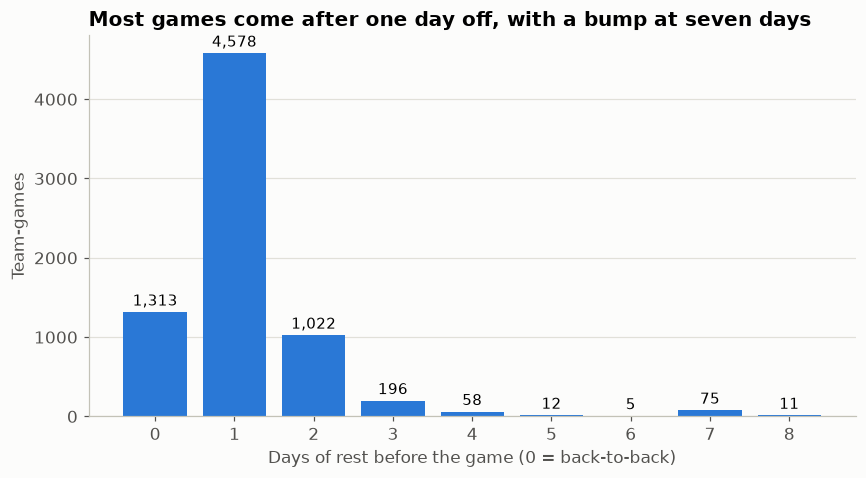

Rest over 5 days, by All-Star break flag:
ALL_STAR_BREAK
True     90
False     1
Name: count, dtype: int64


In [9]:
rest_counts = df["REST_DAYS"].value_counts().sort_index()

fig, ax = plt.subplots()
bars = ax.bar(rest_counts.index, rest_counts.values, color=BLUE, width=0.8)
ax.bar_label(bars, fmt="{:,.0f}", padding=2, fontsize=10)
ax.set_title("Most games come after one day off, with a bump at seven days")
ax.set_xlabel("Days of rest before the game (0 = back-to-back)")
ax.set_ylabel("Team-games")
ax.grid(axis="x", visible=False)
ax.set_xticks(range(0, 9))
plt.show()

long_rest = df[df["REST_DAYS"] > 5]
print("Rest over 5 days, by All-Star break flag:")
print(long_rest["ALL_STAR_BREAK"].value_counts())

**What to notice**

- One day off is by far the most common, and back-to-backs (0 days) come next.
- The bump at 7 days is the All-Star break. It's the schedule, not a coaching choice, so those games are different from normal rest.
- All but one of the long rests fall on the break. Try finding that one game and looking up what happened.

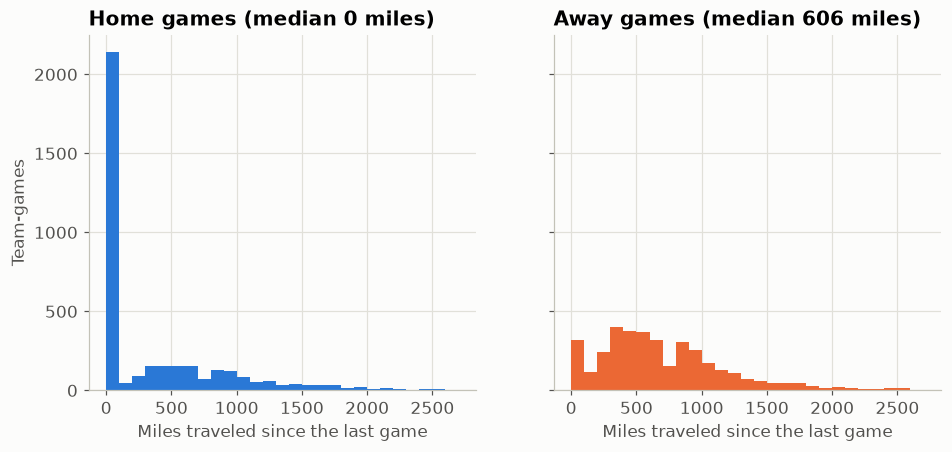

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
bins = range(0, 2800, 100)

for ax, place, color in zip(axes, ["Home", "Away"], [BLUE, ORANGE]):
    miles = df.loc[df["LOCATION_TYPE"] == place, "TRAVEL_DISTANCE_MILES"]
    ax.hist(miles, bins=bins, color=color)
    ax.set_title(f"{place} games (median {miles.median():,.0f} miles)")
    ax.set_xlabel("Miles traveled since the last game")

axes[0].set_ylabel("Team-games")
plt.show()

**What to notice**

- The home histogram is piled up at zero: if your last game was also at home, you didn't travel. That's over half of all home games.
- Because of that spike, the home *average* (about 350 miles) describes almost nobody. **Skewed data is why we look at the shape first, and often prefer the median.**

## 4. How do groups compare?

We combine 3 or more days into one group, because the larger values have very few games.

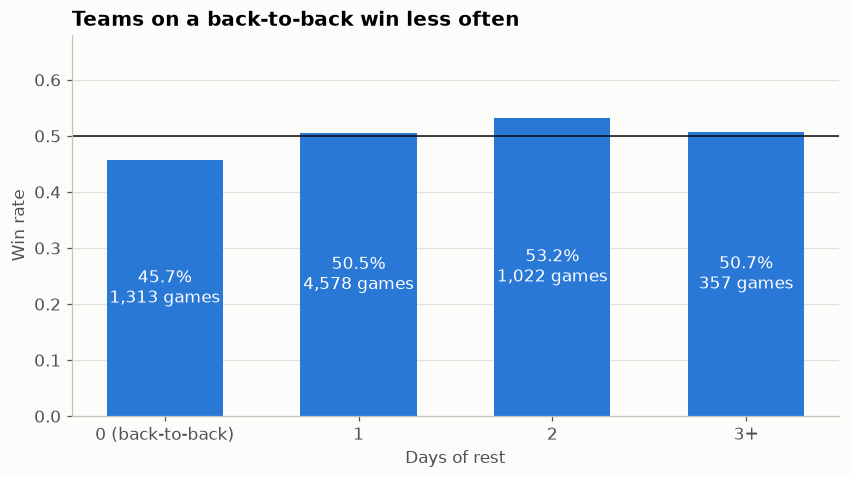

In [11]:
df["rest_group"] = df["REST_DAYS"].clip(upper=3)  # 3 now means "3 or more"
labels = ["0 (back-to-back)", "1", "2", "3+"]

summary = df.groupby("rest_group")["win"].agg(["mean", "size"])

fig, ax = plt.subplots()
bars = ax.bar(labels, summary["mean"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{m:.1%}\n{n:,} games" for m, n in zip(summary["mean"], summary["size"])],
             label_type="center", color="white")
ax.axhline(0.5, color=INK, linewidth=1)
ax.set_ylim(0, 0.68)
ax.set_title("Teams on a back-to-back win less often")
ax.set_xlabel("Days of rest")
ax.set_ylabel("Win rate")
ax.grid(axis="x", visible=False)
plt.show()

**Before believing this, ask: what else could explain it?** Maybe back-to-backs are mostly road games, and road teams lose more anyway. We can test that by splitting the chart by home and away.

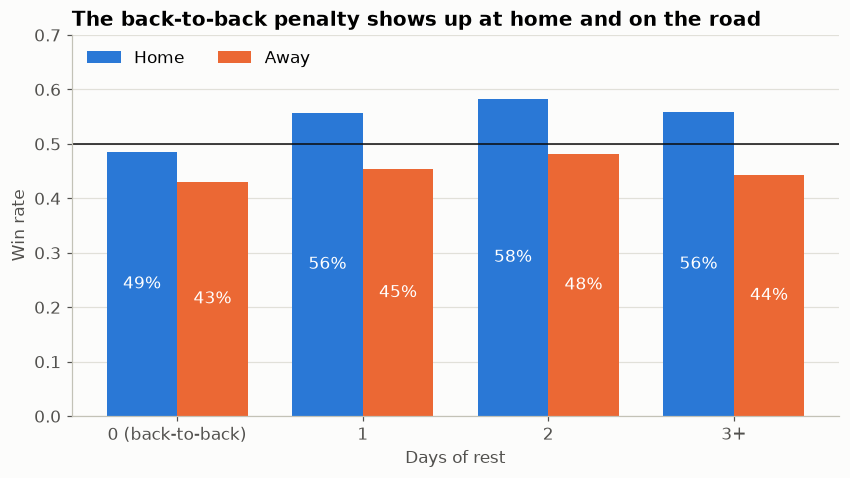

Share of each rest group that are road games:
rest_group
0.0    0.513
1.0    0.501
2.0    0.498
3.0    0.443
Name: LOCATION_TYPE, dtype: float64


In [12]:
split = df.groupby(["rest_group", "LOCATION_TYPE"])["win"].mean().unstack()
x = np.arange(4)
width = 0.38

fig, ax = plt.subplots()
home_bars = ax.bar(x - width / 2, split["Home"], width, color=BLUE, label="Home")
away_bars = ax.bar(x + width / 2, split["Away"], width, color=ORANGE, label="Away")
ax.bar_label(home_bars, fmt="{:.0%}", label_type="center", color="white")
ax.bar_label(away_bars, fmt="{:.0%}", label_type="center", color="white")
ax.axhline(0.5, color=INK, linewidth=1)
ax.set_xticks(x, labels)
ax.set_ylim(0, 0.7)
ax.set_title("The back-to-back penalty shows up at home and on the road")
ax.set_xlabel("Days of rest")
ax.set_ylabel("Win rate")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncols=2)
plt.show()

print("Share of each rest group that are road games:")
print(df.groupby("rest_group")["LOCATION_TYPE"].apply(lambda s: (s == "Away").mean()).round(3))

**What to notice**

- Back-to-backs are about half road games, the same as any other group, so location doesn't explain the gap.
- The penalty appears in both groups, and looks larger for home teams. **Splitting by a third variable is one of the most useful habits in EDA.**
- Win rate doesn't keep climbing past two days of rest. The 3+ group is small and mixes in the All-Star break.

### Does the *opponent's* rest matter too?

A team's rest only matters relative to the other team. `single_game.csv` has both teams on one row, so we can compare them directly.

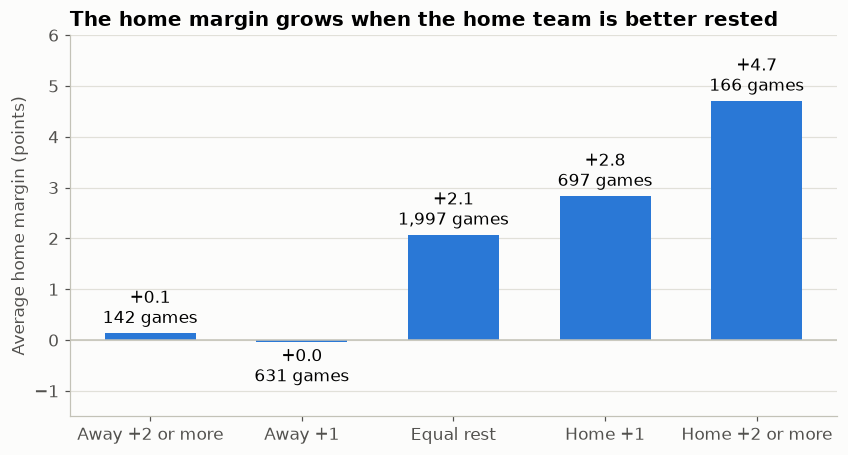

In [13]:
# Positive = the home team had more rest. PLUS_MINUS here is the home team's margin.
rested = games.dropna(subset=["REST_DAYS_home", "REST_DAYS_away"]).copy()
rested["rest_edge"] = (rested["REST_DAYS_home"] - rested["REST_DAYS_away"]).clip(-2, 2)

edge = rested.groupby("rest_edge")["PLUS_MINUS"].agg(["mean", "size"])
edge_labels = ["Away +2 or more", "Away +1", "Equal rest", "Home +1", "Home +2 or more"]

fig, ax = plt.subplots()
bars = ax.bar(edge_labels, edge["mean"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{round(m, 1) + 0:+.1f}\n{n:,} games" for m, n in zip(edge["mean"], edge["size"])], padding=3)
ax.set_ylim(-1.5, 6)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1)
ax.set_title("The home margin grows when the home team is better rested")
ax.set_ylabel("Average home margin (points)")
ax.grid(axis="x", visible=False)
plt.show()

**What to notice**

- With equal rest, home teams win by about 2 points, the same home edge the Home Court team finds.
- That margin rises to nearly 5 with a two-day rest edge, and disappears when the away team has that edge.
- The two ends of the chart have only about 150 games each, so those numbers are less certain than the middle.

### Does distance hurt?

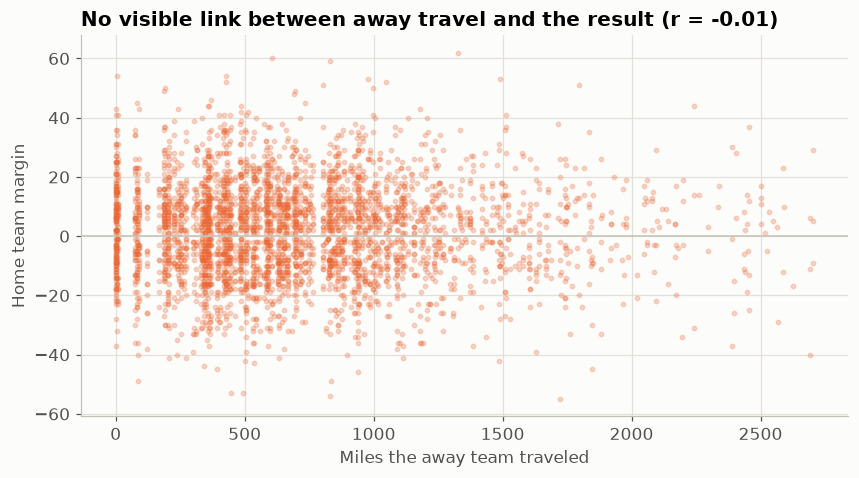

In [14]:
r = games["TRAVEL_DISTANCE_MILES_away"].corr(games["PLUS_MINUS"])

fig, ax = plt.subplots()
ax.scatter(games["TRAVEL_DISTANCE_MILES_away"], games["PLUS_MINUS"], s=8, alpha=0.25, color=ORANGE)
ax.axhline(0, color=LIGHT_GRAY, linewidth=1)
ax.set_title(f"No visible link between away travel and the result (r = {r:.2f})")
ax.set_xlabel("Miles the away team traveled")
ax.set_ylabel("Home team margin")
plt.show()

In [15]:
# A scatter can hide small effects, so also compare averages across distance groups
bands = pd.cut(games["TRAVEL_DISTANCE_MILES_away"], [-1, 500, 1000, 1500, 3000],
               labels=["0-500", "500-1,000", "1,000-1,500", "1,500+"])
games.groupby(bands, observed=True)["PLUS_MINUS"].agg(["mean", "size"]).round(2)

,mean,size
TRAVEL_DISTANCE_MILES_away,,
0-500,1.79,1456
"500-1,000",2.16,1409
"1,000-1,500",1.83,543
"1,500+",0.71,272


**What to notice**

- The cloud is flat, and r is about zero. Mileage on its own tells us very little about the result.
- A flat result is still a result. It suggests the project should focus on rest rather than distance.
- The 1,500+ mile group has a somewhat lower home margin, but with only 272 games the gap is within normal noise. If anything, it runs the "wrong" way, which is worth a closer look.

## 5. Who travels the most, and does it change over time?

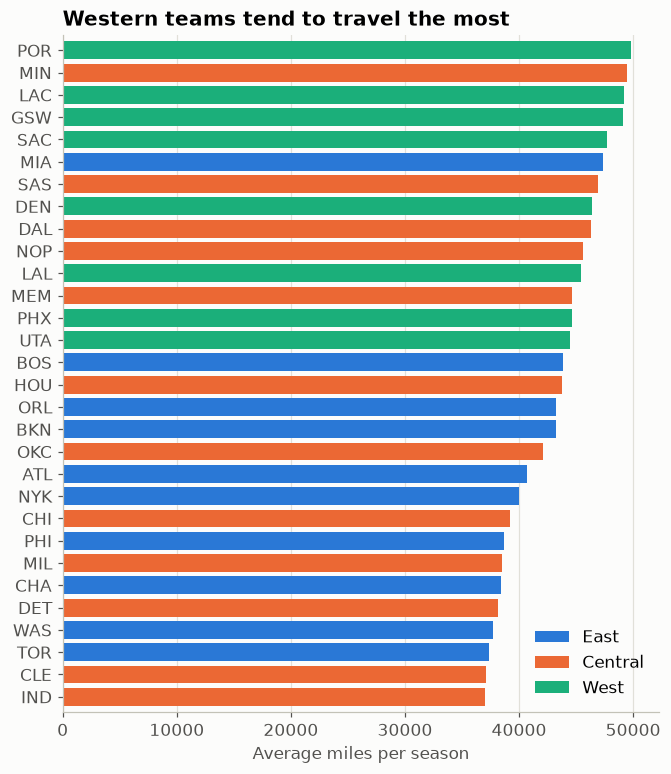

In [16]:
per_team = df.groupby(["TEAM_ABBREVIATION", "REGION"])["TRAVEL_DISTANCE_MILES"].sum().div(3).reset_index()
per_team = per_team.sort_values("TRAVEL_DISTANCE_MILES")

region_colors = {"East": BLUE, "Central": ORANGE, "West": AQUA}

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(per_team["TEAM_ABBREVIATION"], per_team["TRAVEL_DISTANCE_MILES"],
        color=per_team["REGION"].map(region_colors))
for region, color in region_colors.items():
    ax.barh([0], [0], color=color, label=region)
ax.legend(loc="lower right")
ax.set_title("Western teams tend to travel the most")
ax.set_xlabel("Average miles per season")
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
plt.show()

In [17]:
df.groupby("SEASON").agg(
    games=("win", "size"),
    back_to_back_share=("REST_DAYS", lambda s: (s == 0).mean()),
    avg_miles=("TRAVEL_DISTANCE_MILES", "mean"),
).round(3)

,games,back_to_back_share,avg_miles
SEASON,,,
2023-24,2460,0.172,516.788
2024-25,2450,0.184,533.033
2025-26,2450,0.180,535.032


**What to notice**

- Geography shapes the schedule: four of the five longest-traveling teams are in the West region, and the ten shortest are all East or Central. There are exceptions, like Minnesota and Miami, so location isn't the whole story.
- With only three seasons of data, we can't say much about long-term trends.

## 6. What should we ask next?

**What we learned**

- Back-to-backs have a clear cost: about a 46% win rate, compared with about 51% after one day off.
- The *difference* in rest between teams seems to matter more than a team's own rest.
- Raw distance shows almost no relationship with the margin.

**Your turn**

1. Do time zones matter more than miles? `UTC_OFFSET_HOURS` lets you test whether west-to-east trips are harder than the reverse.
2. Is a back-to-back worse when the first game was far away?
3. Should All-Star-break games be removed from the rest analysis? Try it both ways and see if the charts change.